# Recalage de niveau des prévisions sur les données de production

**Question :** pourquoi les prévisions du champion sont-elles trop hautes en production, et le recalage de niveau (prévision × ratio mesuré / prévu) corrige-t-il le problème ?

Le notebook rejoue les prévisions sur les heures réellement mesurées en production (API Mock), comme le fait `prediction-jobs` : à chaque heure, prévision des 24 heures suivantes avec uniquement le passé. Le ratio est calculé par **la fonction de production** `level_ratios` de `services/prediction-service/src/prediction_service/recalibration.py` ; le champion est reconstruit à partir de `train.parquet` avec `configs/hgb_production.yaml`.

### Lancer le notebook

Depuis la racine du projet, avec `.data/ml/splits/train.parquet` (voir `training.prepare_data`) et les métadonnées des sites dans `.data/ml/raw/metadata/` :

~~~bash
scripts/ml/export-prod-hours.sh            # lecture seule (SSM) vers .data/ml/prod/
python3 -m venv services/ml-service/notebook/.venv
source services/ml-service/notebook/.venv/bin/activate
python -m pip install -r services/ml-service/requirements-notebooks.txt
python -m jupyterlab services/ml-service/notebook/02_recalage_niveau_prod.ipynb
~~~

**.data/** est ignoré par Git : les données de production ne sont pas versionnées. **Restart Kernel and Run All Cells** recalcule tout ; les chiffres évoluent à mesure que la production accumule des heures.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from IPython.display import Markdown, display

%matplotlib inline
sns.set_theme(style="whitegrid", palette="colorblind")
pd.options.display.float_format = "{:.3f}".format
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "services/ml-service/requirements-notebooks.txt").is_file())
for path in (ROOT / "services/ml-service", ROOT / "services/prediction-service/src"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
from training.models import build_pipeline
from training.prepare_data import load_site_schedules
from prediction_service.recalibration import WINDOW_HOURS, level_ratios

PROD = ROOT / ".data/ml/prod"
TARGET = "consumption_kwh"
HORIZON = 24  # next 24 hours forecast, like prediction-jobs

## 1. Données et champion

Heures de `readings_hours` en UTC (les heures de travail de l'API Mock ne suivent pas l'heure d'été). Les heures dont la consommation repose sur moins de 10 minutes sont écartées, comme dans `read_measured_hours` : avec `/current`, l'API Mock ne renvoie la consommation que sur 18 à 32 minutes par heure environ. Le champion est le HGB de production, réentraîné ici sur `train.parquet` ; on vérifie qu'il reproduit les prévisions brutes publiées en production.

In [2]:
hours = pd.read_csv(PROD / "readings_hours.csv")
hours["timestamp"] = pd.to_datetime(hours.ts, utc=True).dt.tz_convert(None)
hours = hours[hours[TARGET].notna() & hours.minutes_consumption.fillna(60).ge(10)]
measured = hours.set_index(["site_id", "timestamp"])[TARGET]
SITES = sorted(hours.site_id.unique())
SCHEDULES = load_site_schedules(ROOT / ".data/ml/raw/metadata", SITES)

config = yaml.safe_load((ROOT / "services/ml-service/configs/hgb_production.yaml").read_text())
train = pd.read_parquet(ROOT / ".data/ml/splits/train.parquet")
champion, _ = build_pipeline(config["model"], config["features"], config["parameters"])
champion.fit(train[config["features"]], train[TARGET])


def calendar(site, timestamps):
    start, end = SCHEDULES[site]["working_hours"]
    ts = pd.DatetimeIndex(timestamps)
    return pd.DataFrame({
        "site_id": site, "hour": ts.hour, "day_of_week": ts.dayofweek, "month": ts.month,
        "is_working_hours": (ts.dayofweek.isin(SCHEDULES[site]["working_days"])
                             & (ts.hour >= start) & (ts.hour < end)).astype(int),
    }, index=ts)


# Raw champion forecast for each hour of the period.
grid = pd.date_range(hours.timestamp.min() - pd.Timedelta(hours=WINDOW_HOURS),
                     hours.timestamp.max() + pd.Timedelta(hours=HORIZON), freq="h")
frames = []
for site in SITES:
    features = calendar(site, grid)
    features["champion"] = champion.predict(features[config["features"]])
    frames.append(features.rename_axis("timestamp").reset_index())
calendar_grid = pd.concat(frames).set_index(["site_id", "timestamp"])

published = pd.read_csv(PROD / "predictions.csv")
published["timestamp"] = pd.to_datetime(published.predicted_for, utc=True).dt.tz_convert(None)
recent = published[pd.to_datetime(published.generated_at, utc=True) >= pd.Timestamp("2026-10-27 10:55", tz="UTC")]
gap = (recent.join(calendar_grid.champion, on=["site_id", "timestamp"]).eval("champion - prediction_kwh").abs())
display(Markdown(
    f"**{len(hours):,} heures mesurées**, {len(SITES)} sites, du {hours.timestamp.min():%d/%m %H:%M} "
    f"au {hours.timestamp.max():%d/%m %H:%M} UTC. Écart moyen entre ce champion et les prévisions "
    f"publiées en production (séries en UTC, avant recalage) : **{gap.mean():.1f} kWh** sur {len(gap)} heures."
))

**1,001 heures mesurées**, 7 sites, du 21/10 12:00 au 27/10 11:00 UTC. Écart moyen entre ce champion et les prévisions publiées en production (séries en UTC, avant recalage) : **0.0 kWh** sur 175 heures.

## 2. Le constat : un facteur d'échelle par site, stable d'un jour à l'autre

Ratio journalier = consommation mesurée du jour / prévision du champion pour les mêmes heures. Si la forme apprise est juste et que seule l'échelle diffère, ce ratio est presque constant pour un site.

jour,Wed 21/10,Thu 22/10,Fri 23/10,Sat 24/10,Sun 25/10,Mon 26/10,Tue 27/10
site_id,,,,,,,
SITE001,0.754,0.780,0.755,0.748,0.746,0.773,0.749
SITE002,0.823,0.820,0.829,0.782,0.774,0.819,0.816
SITE003,0.778,0.776,0.779,0.762,0.773,0.778,0.777
SITE004,0.711,0.712,0.714,0.957,0.959,0.706,0.719
SITE005,0.802,0.788,0.793,0.792,0.790,0.792,0.787
SITE006,0.661,0.659,0.662,0.666,0.672,0.662,0.664
SITE007,0.776,0.770,0.782,0.722,0.725,0.774,0.760


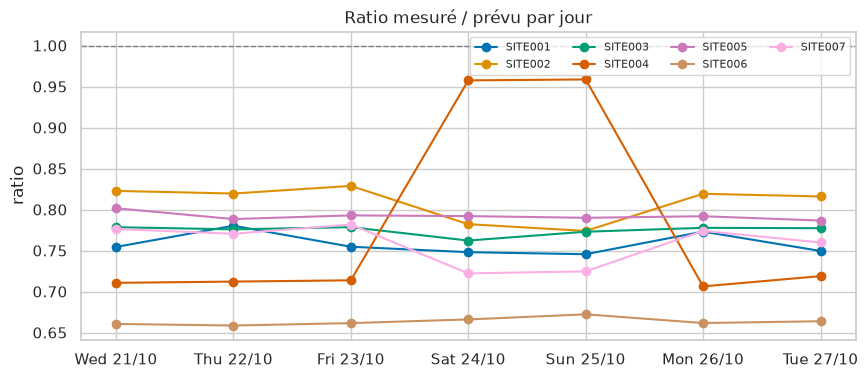

is_working_hours,heures non travaillées,heures travaillées
site_id,,
SITE001,0.733,0.789
SITE002,0.762,0.838
SITE003,NaN,0.774
SITE004,1.018,0.702
SITE005,NaN,0.792
SITE006,0.657,0.669
SITE007,0.704,0.793


In [3]:
daily = hours.join(calendar_grid[["champion", "is_working_hours"]], on=["site_id", "timestamp"])
daily["jour"] = daily.timestamp.dt.strftime("%a %d/%m")
ratios_by_day = (daily.groupby(["site_id", "jour"], sort=False)[[TARGET, "champion"]].sum()
                 .eval(f"{TARGET} / champion").unstack())
display(ratios_by_day)

fig, ax = plt.subplots(figsize=(10, 4))
ratios_by_day.T.plot(ax=ax, marker="o")
ax.axhline(1, color="grey", linewidth=1, linestyle="--")
ax.set(title="Ratio mesuré / prévu par jour", xlabel="", ylabel="ratio")
ax.legend(ncol=4, fontsize=8)
plt.show()

by_group = (daily.groupby(["site_id", "is_working_hours"])[[TARGET, "champion"]].sum()
            .eval(f"{TARGET} / champion").unstack().rename(columns={0: "heures non travaillées", 1: "heures travaillées"}))
display(by_group)

**Lecture :** l'API Mock reproduit les profils du CSV multipliés par un facteur propre à chaque site (environ 0,66 à 0,83). Le centre commercial (SITE004) fait exception : son surplus du week-end, présent dans le CSV, n'existe pas dans l'API Mock. L'écart diffère aussi un peu entre heures travaillées et non travaillées, d'où un ratio par groupe.

## 3. Backtest

À chaque heure d'origine, pour chaque site, chaque variante prévoit les 24 heures suivantes avec les seules heures mesurées avant l'origine :

| Variante | Prévision |
| --- | --- |
| `champion` | Prévision brute du modèle (ce qui était publié avant le recalage) |
| `ratio global` | Champion × ratio du site sur 7 jours, toutes heures confondues |
| `recalage (production)` | Champion × ratio du groupe de l'heure (travaillée ou non), règles de `level_ratios` : 7 jours, au moins 24 heures, bornes 0,5 et 1,5 |
| `profil récent` | Référence sans modèle : moyenne de la même heure les jours passés du même type (semaine ou week-end) |

Score : nMAE par site, `100 × moyenne(|réel − prévu|) / moyenne(réel)`, puis moyenne des sites (même définition que l'entraînement). Biais : `100 × Σ(prévu − réel) / Σ réel`.

In [4]:
start = hours.timestamp.min() + pd.Timedelta(hours=72)  # at least 3 days of history
origins = pd.date_range(start.ceil("h"), hours.timestamp.max() - pd.Timedelta(hours=1), freq="h")
rows = []
for site in SITES:
    site_grid = calendar_grid.loc[site]
    site_measured = measured.loc[site]
    for origin in origins:
        window = site_measured[(site_measured.index >= origin - pd.Timedelta(hours=WINDOW_HOURS))
                               & (site_measured.index < origin)]
        past = site_grid.loc[window.index]
        ratios = level_ratios(zip(past.is_working_hours, window, past.champion))
        global_ratio = ratios.overall
        for k in range(1, HORIZON + 1):
            target = origin + pd.Timedelta(hours=k)
            if target not in site_measured.index:
                continue
            raw, working = site_grid.at[target, "champion"], site_grid.at[target, "is_working_hours"]
            same_type = [target - pd.Timedelta(days=d) for d in range(1, 8)
                         if target - pd.Timedelta(days=d) < origin
                         and ((target - pd.Timedelta(days=d)).dayofweek >= 5) == (target.dayofweek >= 5)]
            profile = site_measured.reindex(same_type).dropna()
            rows.append({
                "site_id": site, "origin": origin, "timestamp": target, "réel": site_measured.at[target],
                "champion": raw, "ratio global": raw * global_ratio,
                "recalage (production)": raw * ratios.for_hour(working),
                "profil récent": profile.mean() if len(profile) else np.nan,
            })
backtest = pd.DataFrame(rows)
VARIANTS = ["champion", "ratio global", "recalage (production)", "profil récent"]


def scores(frame):
    result = {}
    for variant in VARIANTS:
        part = frame.dropna(subset=[variant])
        nmae = part.groupby("site_id").apply(
            lambda g: 100 * (g[variant] - g["réel"]).abs().mean() / g["réel"].mean(), include_groups=False)
        result[variant] = {"nMAE macro (%)": nmae.mean(),
                           "biais (%)": 100 * (part[variant] - part["réel"]).sum() / part["réel"].sum(),
                           "prévisions": len(part), **nmae.rename(lambda s: f"{s} (%)").to_dict()}
    return pd.DataFrame(result).T


pd.options.display.float_format = "{:.1f}".format
display(Markdown(f"**{len(backtest):,} prévisions** évaluées, origines du {origins[0]:%d/%m %H:%M} "
                 f"au {origins[-1]:%d/%m %H:%M} UTC."))
display(scores(backtest))

**9,996 prévisions** évaluées, origines du 24/10 12:00 au 27/10 10:00 UTC.

,nMAE macro (%),biais (%),prévisions,SITE001 (%),SITE002 (%),SITE003 (%),SITE004 (%),SITE005 (%),SITE006 (%),SITE007 (%)
champion,34.1,28.6,9996.0,32.9,24.1,28.9,43.8,26.5,50.2,32.0
ratio global,8.1,0.4,9996.0,5.5,5.9,4.8,25.7,5.2,3.2,6.4
recalage (production),7.5,0.2,9996.0,4.9,4.8,4.8,25.0,5.2,3.0,4.6
profil récent,1.3,0.1,9450.0,4.4,0.9,0.8,0.7,0.7,0.6,0.8


Le `profil récent` n'est calculé que lorsqu'un jour du même type existe dans le passé (moins de prévisions) : c'est une **référence**, pas un candidat. L'API Mock est presque périodique ; rejouer les jours précédents y est donc très efficace, ce qui ne serait pas le cas sur de vraies données (météo, jours fériés, tendances).

## 4. Prévu et mesuré

Prévisions émises 12 heures avant chaque heure, sur les trois derniers jours : un bureau (forme et niveau corrigés) et le centre commercial (cas où le ratio ne suffit pas le week-end).

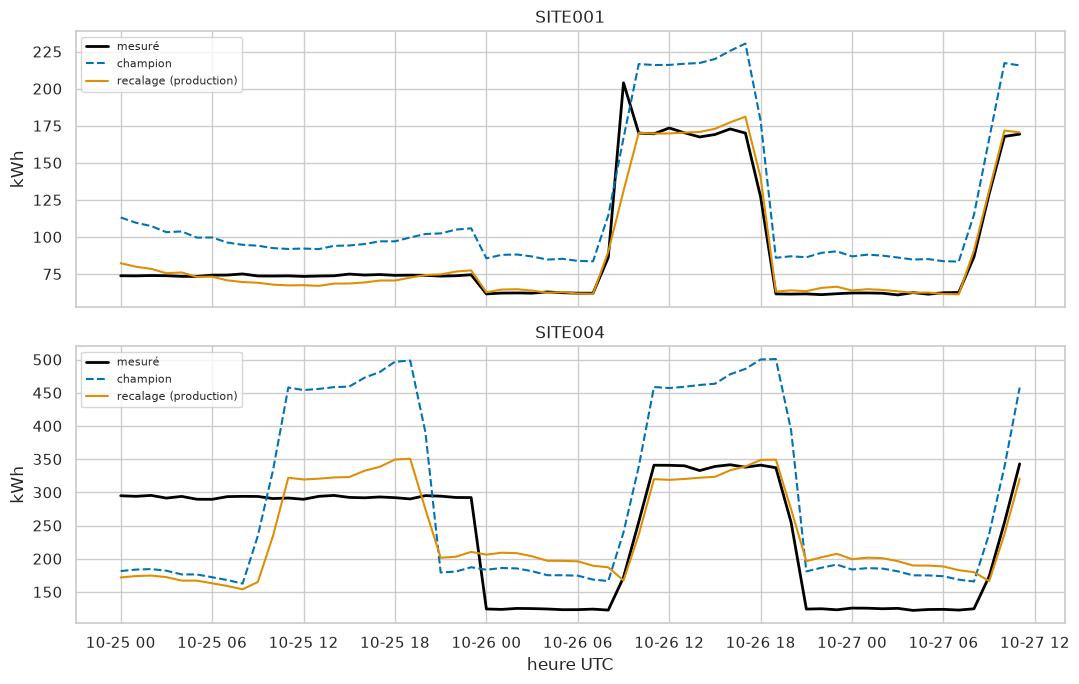

**nMAE macro (%) par jour prévu :**

,champion,ratio global,recalage (production),profil récent
jour,,,,
Sat 24/10,38.0,11.2,8.3,NaN
Sun 25/10,32.1,9.4,7.8,0.7
Mon 26/10,28.7,6.0,5.8,0.9
Tue 27/10,29.1,5.9,6.4,1.1


In [5]:
last = backtest[(backtest.timestamp - backtest.origin) == pd.Timedelta(hours=12)]
last = last[last.timestamp >= last.timestamp.max() - pd.Timedelta(days=3)]
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, site in zip(axes, ["SITE001", "SITE004"]):
    # Missing hours left empty: no segment drawn across a data gap.
    part = last[last.site_id == site].set_index("timestamp").asfreq("h")
    ax.plot(part.index, part["réel"], color="black", linewidth=2, label="mesuré")
    ax.plot(part.index, part["champion"], linestyle="--", label="champion")
    ax.plot(part.index, part["recalage (production)"], label="recalage (production)")
    ax.set(title=site, ylabel="kWh")
    ax.legend(fontsize=8)
axes[-1].set_xlabel("heure UTC")
plt.tight_layout()
plt.show()

pd.options.display.float_format = "{:.1f}".format
display(Markdown("**nMAE macro (%) par jour prévu :**"))


def daily_nmae(group):
    # Hours without a value for the variant are dropped.
    return pd.Series({v: 100 * (part[v] - part["réel"]).abs().sum() / part["réel"].sum()
                      if len(part := group.dropna(subset=[v])) else np.nan for v in VARIANTS})


display(backtest.assign(jour=backtest.timestamp.dt.strftime("%a %d/%m"))
        .groupby("jour", sort=False).apply(daily_nmae, include_groups=False))

## 5. Conclusions

- **Le problème est l'échelle, pas la forme.** Le champion place correctement les heures de montée et de descente (features en UTC), mais il surestime d'environ 30 %. Le ratio mesuré / prévu de chaque site est stable d'un jour à l'autre.
- **Le recalage supprime le biais** et divise l'erreur par quatre environ, sans réentraîner ni modifier le modèle : c'est ce qu'applique désormais `prediction-jobs` (`recalibration.py`). La prévision brute et le ratio sont enregistrés avec chaque valeur publiée (`predictions.model_prediction_kwh`, `predictions.level_ratio`).
- **Limites :** le week-end du centre commercial reste mal prévu ; un changement brutal de niveau n'est suivi qu'en quelques jours ; le recalage masque la dérive dans l'erreur publiée, d'où le suivi séparé de l'erreur du champion seul et du ratio.
- **Suite :** réentraîner un challenger sur les données de l'API Mock quand plusieurs semaines seront disponibles ; il devra battre le champion recalé, et le `profil récent` sert de référence à dépasser.